In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
print(f"Using Scikit-Learn version: {sklearn.__version__}")

Using Scikit-Learn version: 1.9.0


In [2]:
dados = pd.read_csv("dados/relatorio.csv")

In [3]:
dados.describe()

,Ano de Conclusão do Ensino Anterior,Ano de Ingresso,C.R.,Idade,Município de Residência (Código IBGE),Período Atual,Período de Ingresso
count,279.000000,279.000000,279.000000,279.000000,2.790000e+02,279.000000,279.000000
mean,2018.197133,2024.494624,518.218638,26.906810,4.320674e+06,2.405018,1.039427
std,6.905362,1.324563,368.592968,7.923096,4.204140e+03,1.794509,0.194957
min,1985.000000,2022.000000,0.000000,18.000000,4.301008e+06,1.000000,1.000000
25%,2015.000000,2024.000000,45.000000,21.000000,4.322608e+06,1.000000,1.000000
50%,2021.000000,2025.000000,696.000000,24.000000,4.322608e+06,2.000000,1.000000
75%,2023.000000,2026.000000,833.000000,31.000000,4.322608e+06,3.000000,1.000000
max,2025.000000,2026.000000,993.000000,66.000000,4.323804e+06,6.000000,2.000000


In [8]:
dados.dtypes

Matrícula                                  str
Aluno Especial                             str
Ano de Conclusão do Ensino Anterior      int64
Ano de Ingresso                          int64
Bairro                                     str
C.R.                                     int64
Cidade                                     str
Data de Matrícula                          str
Data de Nascimento                         str
Deficiências                               str
Estado Civil                               str
Etnia/Raça                                 str
Forma de Ingresso                          str
Frequência no Período                      str
Idade                                    int64
Município de Residência                    str
Município de Residência (Código IBGE)    int64
Média Final no Período                     str
Nacionalidade                              str
Naturalidade                               str
Natureza de Participação                   str
Nome da Escol

In [9]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 279 entries, 0 to 278
Data columns (total 38 columns):
 #   Column                                 Non-Null Count  Dtype
---  ------                                 --------------  -----
 0   Matrícula                              279 non-null    str  
 1   Aluno Especial                         279 non-null    str  
 2   Ano de Conclusão do Ensino Anterior    279 non-null    int64
 3   Ano de Ingresso                        279 non-null    int64
 4   Bairro                                 279 non-null    str  
 5   C.R.                                   279 non-null    int64
 6   Cidade                                 279 non-null    str  
 7   Data de Matrícula                      279 non-null    str  
 8   Data de Nascimento                     279 non-null    str  
 9   Deficiências                           279 non-null    str  
 10  Estado Civil                           279 non-null    str  
 11  Etnia/Raça                             279 

In [10]:
dados.groupby(["Situação no Curso"]).count()

,Matrícula,Aluno Especial,Ano de Conclusão do Ensino Anterior,Ano de Ingresso,Bairro,C.R.,Cidade,Data de Matrícula,Data de Nascimento,Deficiências,...,Sexo,Tipo de Escola de Origem,Tipo de Oferta,Turno,Zona Residencial,Colação de Grau Pendente,Atividades Complementares Pendente,Carga Horária Eletiva Pendente,Carga Horária Optativa Pendente,Carga Horária Obrigatória Pendente
Situação no Curso,,,,,,,,,,,,,,,,,,,,,
Cancelado,52,52,52,52,52,52,52,52,52,52,...,52,52,52,52,52,52,52,52,52,52
Cancelamento Compulsório,4,4,4,4,4,4,4,4,4,4,...,4,4,4,4,4,4,4,4,4,4
Evasão,46,46,46,46,46,46,46,46,46,46,...,46,46,46,46,46,46,46,46,46,46
Formado,25,25,25,25,25,25,25,25,25,25,...,25,25,25,25,25,25,25,25,25,25
Matriculado,147,147,147,147,147,147,147,147,147,147,...,147,147,147,147,147,147,147,147,147,147
Trancado,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
Trancado Voluntariamente,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2


In [11]:
dados

,Matrícula,Aluno Especial,Ano de Conclusão do Ensino Anterior,Ano de Ingresso,Bairro,C.R.,Cidade,Data de Matrícula,Data de Nascimento,Deficiências,...,Situação no Curso,Tipo de Escola de Origem,Tipo de Oferta,Turno,Zona Residencial,Colação de Grau Pendente,Atividades Complementares Pendente,Carga Horária Eletiva Pendente,Carga Horária Optativa Pendente,Carga Horária Obrigatória Pendente
0,20231VA.ADS0035,Não,2002,2023,Xangrila,469,Venâncio Aires,11/04/2023 19:00:09,03/02/1984,Baixa visão,...,Evasão,Pública,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim
1,20251VA.ADS0018,Não,2025,2025,Bela Vista,248,Venâncio Aires,24/01/2025 15:54:36,18/05/2004,-,...,Cancelado,Pública,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim
2,20241VA.ADS0024,Não,2023,2024,CENTRO,872,Venâncio Aires,11/03/2024 14:19:53,18/05/2005,-,...,Matriculado,Pública,Tecnologia,Noite,Urbana,Sim,Não,Não,Não,Sim
3,20251VA.ADS0029,Não,1985,2025,Centro,0,Venâncio Aires,26/02/2025 08:09:22,24/02/1969,-,...,Cancelado,Privada,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim
4,20241VA.ADS0023,Não,2018,2024,Renascença,76,SANTA CRUZ DO SUL,08/03/2024 08:42:00,18/11/1999,-,...,Evasão,Pública,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,20241VA.EMC_J0006,Não,2015,2024,Interior,510,Venâncio Aires,16/01/2024 07:26:48,24/07/1990,-,...,Matriculado,Pública,Bacharelado,Noite,Rural,Sim,Sim,Não,Sim,Sim
275,20261VA.CSEM0004,Não,2001,2026,Centro,503,Venâncio Aires,08/01/2026 18:41:41,16/12/1983,-,...,Matriculado,Pública,Bacharelado,Noite,Urbana,Sim,Sim,Não,Sim,Sim
276,20241VA.EM0014,Não,2013,2024,Brigida,600,Venâncio Aires,13/03/2024 16:37:55,02/09/1990,-,...,Matriculado,Privada,Bacharelado,Noite,Urbana,Sim,Sim,Não,Sim,Sim
277,20241VA.EM0015,Não,2015,2024,Americano,145,LAJEADO,18/03/2024 16:01:21,26/07/1995,-,...,Evasão,Privada,Bacharelado,Noite,Urbana,Sim,Sim,Não,Sim,Sim


In [12]:
dados['Situação no Curso'].value_counts()

Situação no Curso
Matriculado                 147
Cancelado                    52
Evasão                       46
Formado                      25
Cancelamento Compulsório      4
Trancado                      3
Trancado Voluntariamente      2
Name: count, dtype: int64

# Manipulando dados

## Situação no Curso

In [13]:
dados['Situação no Curso'] = dados['Situação no Curso'].replace({'Trancado Voluntariamente': 'Trancado'})

In [14]:
dados['Situação no Curso'].value_counts()

Situação no Curso
Matriculado                 147
Cancelado                    52
Evasão                       46
Formado                      25
Trancado                      5
Cancelamento Compulsório      4
Name: count, dtype: int64

In [15]:
dados['Situação no Curso'] = dados['Situação no Curso'].replace({'Cancelamento Compulsório': 'Cancelado'})

In [16]:
# Agora temos somente 5 situações 
dados['Situação no Curso'].value_counts()

Situação no Curso
Matriculado    147
Cancelado       56
Evasão          46
Formado         25
Trancado         5
Name: count, dtype: int64

Vou tentar uma classificação binária: prever se o estudante tem perfil de **Permanência (0)** (Matriculado ou Formado) ou de **Risco/Desistência (1)** (Evasão, Cancelado, Trancado).
Nem precisaria ter feito os dois acima

In [17]:
casos_evasao = ['Cancelado', 'Evasão', 'Trancado', 'Trancado Voluntariamente', 'Cancelamento Compulsório']
dados['target'] = dados['Situação no Curso'].isin(casos_evasao).astype(int)

In [18]:
dados['target'].value_counts()

target
0    172
1    107
Name: count, dtype: int64

## Convertendo colunas em float

In [19]:
cols_numericas = [
    'Percentual de Progresso', 
    'Frequência no Período', 
    'Média Final no Período', 
    'Renda Per Capita'
]

for col in cols_numericas:
    dados[col] = (
        dados[col]
        .astype(str)
        .str.replace(',', '.', regex=False)
        .replace(['-', 'nan', 'None'], np.nan)
    )
    dados[col] = pd.to_numeric(dados[col], errors='coerce')

In [20]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 279 entries, 0 to 278
Data columns (total 39 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Matrícula                              279 non-null    str    
 1   Aluno Especial                         279 non-null    str    
 2   Ano de Conclusão do Ensino Anterior    279 non-null    int64  
 3   Ano de Ingresso                        279 non-null    int64  
 4   Bairro                                 279 non-null    str    
 5   C.R.                                   279 non-null    int64  
 6   Cidade                                 279 non-null    str    
 7   Data de Matrícula                      279 non-null    str    
 8   Data de Nascimento                     279 non-null    str    
 9   Deficiências                           279 non-null    str    
 10  Estado Civil                           279 non-null    str    
 11  Etnia/Raça       

## Criando um atributo de diferença em anos entre ensino médio e ingresso

In [21]:
dados['Anos apos EM'] = dados['Ano de Ingresso'] - dados['Ano de Conclusão do Ensino Anterior']

In [22]:
dados

,Matrícula,Aluno Especial,Ano de Conclusão do Ensino Anterior,Ano de Ingresso,Bairro,C.R.,Cidade,Data de Matrícula,Data de Nascimento,Deficiências,...,Tipo de Oferta,Turno,Zona Residencial,Colação de Grau Pendente,Atividades Complementares Pendente,Carga Horária Eletiva Pendente,Carga Horária Optativa Pendente,Carga Horária Obrigatória Pendente,target,Anos apos EM
0,20231VA.ADS0035,Não,2002,2023,Xangrila,469,Venâncio Aires,11/04/2023 19:00:09,03/02/1984,Baixa visão,...,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim,1,21
1,20251VA.ADS0018,Não,2025,2025,Bela Vista,248,Venâncio Aires,24/01/2025 15:54:36,18/05/2004,-,...,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim,1,0
2,20241VA.ADS0024,Não,2023,2024,CENTRO,872,Venâncio Aires,11/03/2024 14:19:53,18/05/2005,-,...,Tecnologia,Noite,Urbana,Sim,Não,Não,Não,Sim,0,1
3,20251VA.ADS0029,Não,1985,2025,Centro,0,Venâncio Aires,26/02/2025 08:09:22,24/02/1969,-,...,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim,1,40
4,20241VA.ADS0023,Não,2018,2024,Renascença,76,SANTA CRUZ DO SUL,08/03/2024 08:42:00,18/11/1999,-,...,Tecnologia,Noite,Urbana,Sim,Sim,Não,Não,Sim,1,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,20241VA.EMC_J0006,Não,2015,2024,Interior,510,Venâncio Aires,16/01/2024 07:26:48,24/07/1990,-,...,Bacharelado,Noite,Rural,Sim,Sim,Não,Sim,Sim,0,9
275,20261VA.CSEM0004,Não,2001,2026,Centro,503,Venâncio Aires,08/01/2026 18:41:41,16/12/1983,-,...,Bacharelado,Noite,Urbana,Sim,Sim,Não,Sim,Sim,0,25
276,20241VA.EM0014,Não,2013,2024,Brigida,600,Venâncio Aires,13/03/2024 16:37:55,02/09/1990,-,...,Bacharelado,Noite,Urbana,Sim,Sim,Não,Sim,Sim,0,11
277,20241VA.EM0015,Não,2015,2024,Americano,145,LAJEADO,18/03/2024 16:01:21,26/07/1995,-,...,Bacharelado,Noite,Urbana,Sim,Sim,Não,Sim,Sim,1,9


# Selecionando campos a serem usados no treinamento

In [23]:
campos_num =[
    'C.R.', 
    'Frequência no Período', 
    'Média Final no Período', 
    'Percentual de Progresso', 
    'Período Atual', 
    'Idade', 
    'Renda Per Capita', 
    'Anos apos EM',
    'Ano de Ingresso'
]

In [24]:
campos_cat = [
    'Forma de Ingresso', 
    'Tipo de Escola de Origem', 
    'Sexo', 
    'Estado Civil', 
    'Zona Residencial', 
    'Município de Residência'
]

In [25]:
# Criando X com as características 
X_paraFILTRO = pd.get_dummies(dados[campos_num + campos_cat + ["target"]], columns=campos_cat, drop_first=True)
X = X_paraFILTRO.drop(["target"], axis=1)
# Preenche valores faltantes (NaN) com a mediana
X = X.fillna(X.median())
# Criando y com a saída
y = dados["target"]

In [26]:
X

,C.R.,Frequência no Período,Média Final no Período,Percentual de Progresso,Período Atual,Idade,Renda Per Capita,Anos apos EM,Ano de Ingresso,Forma de Ingresso_ENEM - L1,...,Município de Residência_Passo do Sobrado-RS,Município de Residência_Rio Pardo-RS,Município de Residência_Santa Cruz do Sul-RS,Município de Residência_Sinimbu-RS,Município de Residência_Sobradinho-RS,Município de Residência_Taquari-RS,Município de Residência_Vale Verde-RS,Município de Residência_Venâncio Aires-RS,Município de Residência_Vera Cruz-RS,Município de Residência_Xangri-La-RS
0,469,0.00,0.0,29.00,3,42,0.76,21,2023,False,...,False,False,False,False,False,False,False,True,False,False
1,248,0.00,0.0,2.86,1,22,1.39,0,2025,False,...,False,False,False,False,False,False,False,True,False,False
2,872,97.89,6.0,81.19,6,21,2.05,1,2024,False,...,False,False,False,False,False,False,False,True,False,False
3,0,100.00,0.0,17.14,1,57,0.65,40,2025,False,...,False,False,False,False,False,False,False,True,False,False
4,76,0.00,0.0,0.00,1,26,1.39,6,2024,False,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,510,50.68,0.0,15.93,2,36,1.74,9,2024,False,...,False,False,False,False,False,False,False,True,False,False
275,503,88.57,7.5,7.59,1,42,1.39,25,2026,False,...,False,False,False,False,False,False,False,True,False,False
276,600,73.46,0.0,32.24,3,36,2.78,11,2024,False,...,False,False,False,False,False,False,False,True,False,False
277,145,0.00,0.0,2.00,1,31,1.39,9,2024,False,...,False,False,False,False,False,False,False,False,False,False


In [27]:
y

0      1
1      1
2      0
3      1
4      1
      ..
274    0
275    0
276    0
277    1
278    0
Name: target, Length: 279, dtype: int64

In [28]:
y.value_counts()

target
0    172
1    107
Name: count, dtype: int64

In [29]:
# Separando os dados
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,
    y,
    test_size=0.25)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((209, 51), (209,), (70, 51), (70,))

# SVC (Support Vector Classification)

In [30]:
#importando o SVC (Support Vector Classification)
from sklearn import svm
# clf é acrônimo para classification
clf = svm.SVC()
clf.get_params()

{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'rbf',
 'max_iter': -1,
 'probability': 'deprecated',
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [31]:
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [32]:
#sobre a base de treinamento
clf.score(X=X_train,y=y_train)

0.8373205741626795

In [33]:
#sobre a base de teste
clf.score(X=X_test,y=y_test)

0.8285714285714286

In [34]:
y_preds = clf.predict(X_test)
y_preds

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1])

In [35]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
# Create a classification report
print(classification_report(y_test, y_preds))

              precision    recall  f1-score   support

           0       0.80      0.95      0.87        42
           1       0.90      0.64      0.75        28

    accuracy                           0.83        70
   macro avg       0.85      0.80      0.81        70
weighted avg       0.84      0.83      0.82        70



In [36]:
# criando a matriz de confusão
conf_mat = confusion_matrix(y_test, y_preds)
conf_mat

array([[40,  2],
       [10, 18]])

In [37]:
y_test.value_counts()

target
0    42
1    28
Name: count, dtype: int64

Tanto o cálculo do recall e f1-score utilizam os valores expostos na matriz de confusão a seguir:
```
    0   1
0  TN   FN
1  FP   TP
```
TN: True negative. Resultado deu 0, e é 0.\
FP: False positive. Resultado deu 1, mas deveria ser 0.\
FN: False negative. Resultado deu 0, mas deveria ser 1.\
TP: True positive. Resultado deu 1, e é 1.


In [38]:
pd.crosstab(y_test,
y_preds,
rownames=["Target real"],
colnames=["Target predito"])

Target predito,0,1
Target real,,
0,40,2
1,10,18


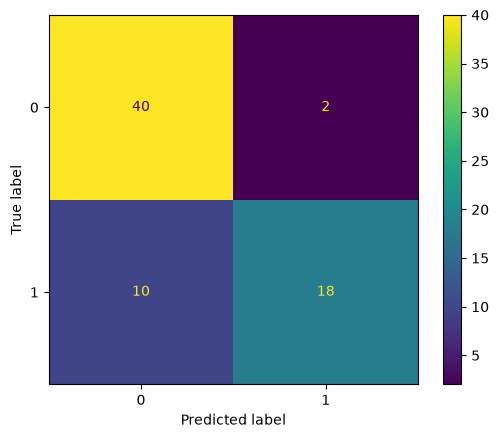

In [39]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_true=y_test,
y_pred=y_preds);

In [40]:
# computando a acurárica
accuracy_score(y_test, y_preds)

0.8285714285714286

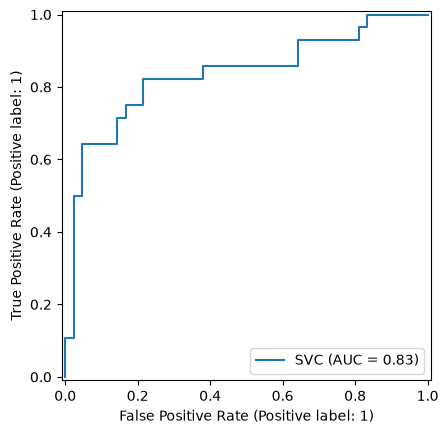

In [41]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clf,
X=X_test,
y=y_test)

# LinearSVC

In [42]:
clfLinear = svm.LinearSVC()
clfLinear.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': 'auto',
 'fit_intercept': True,
 'intercept_scaling': 1,
 'loss': 'squared_hinge',
 'max_iter': 1000,
 'multi_class': 'ovr',
 'penalty': 'l2',
 'random_state': None,
 'tol': 0.0001,
 'verbose': 0}

In [43]:
clfLinear.fit(X_train,y_train)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [44]:
#resultado sobre treinamento
clfLinear.score(X=X_train,y=y_train)

0.9186602870813397

In [45]:
#sobre o teste
clfLinear.score(X=X_test,y=y_test)

0.7857142857142857

In [46]:
y_predsLinear = clf.predict(X_test)
y_predsLinear

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1])

In [47]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
# Create a classification report
print(classification_report(y_test, y_predsLinear))

              precision    recall  f1-score   support

           0       0.80      0.95      0.87        42
           1       0.90      0.64      0.75        28

    accuracy                           0.83        70
   macro avg       0.85      0.80      0.81        70
weighted avg       0.84      0.83      0.82        70



In [48]:
conf_matLinear = confusion_matrix(y_test, y_predsLinear)
conf_matLinear

array([[40,  2],
       [10, 18]])

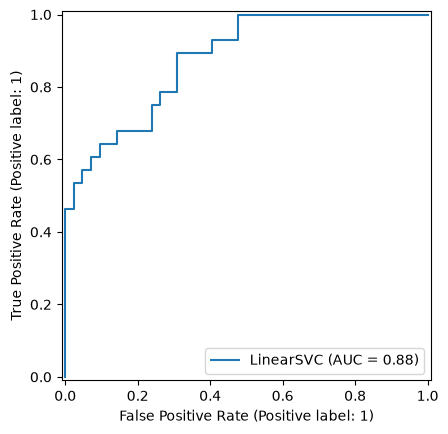

In [49]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clfLinear,
                                                           X=X_test,
                                                           y=y_test)

# RandomForest

In [3]:
from sklearn.ensemble import RandomForestClassifier
clfForest = RandomForestClassifier()
clfForest.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [4]:
clfForest.fit(X_train,y_train)

NameError: name 'X_train' is not defined

In [ ]:
#sobre o treinamento
clfForest.score(X=X_train,y=y_train)

In [53]:
#sobre o teste
clfForest.score(X=X_test,y=y_test)

0.9142857142857143

In [54]:
y_predsForest = clfForest.predict(X_test)
y_predsForest

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1])

In [55]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
conf_matForest = confusion_matrix(y_test, y_predsForest)
conf_matForest

array([[42,  0],
       [ 6, 22]])

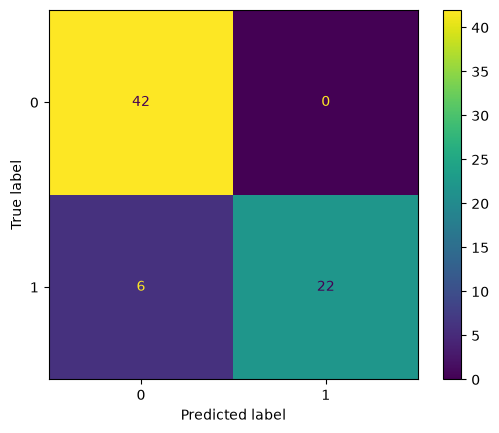

In [68]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_predsForest,
)

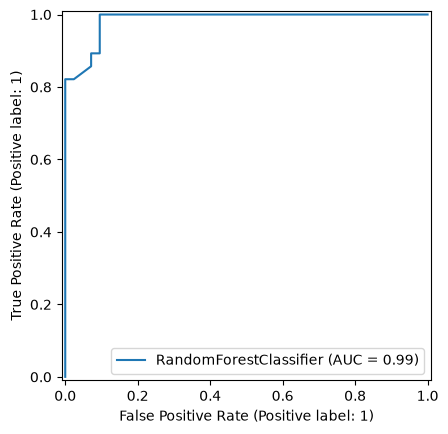

In [57]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clfForest,
                                                   X=X_test,
                                                   y=y_test)


# Árvocres de Descisão

In [58]:
from sklearn.tree import DecisionTreeClassifier
clfTree = DecisionTreeClassifier()
clfTree.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': None,
 'splitter': 'best'}

In [59]:
clfTree.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [60]:
clfTree.score(X=X_train,y=y_train)

1.0

In [64]:
clfTree.score(X=X_test,y=y_test)

0.9285714285714286

In [65]:
y_predsTree = clfTree.predict(X_test)
y_predsTree


array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 1, 1])

In [66]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
conf_matTree = confusion_matrix(y_test, y_predsTree)
conf_matTree

array([[39,  3],
       [ 2, 26]])

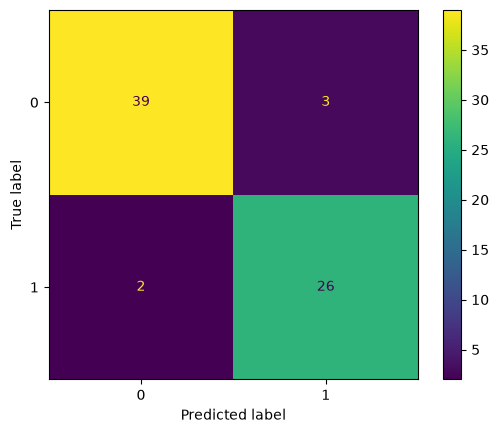

In [69]:
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, 
    y_pred=y_predsTree,
)

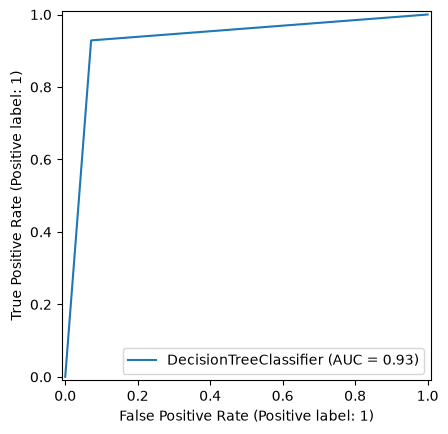

In [70]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clfTree,
                                                  X=X_test,
                                                  y=y_test)

# Naive Bayes


In [71]:
from sklearn.naive_bayes import GaussianNB
clfNB = GaussianNB()
clfNB.get_params()

{'priors': None, 'var_smoothing': 1e-09}

In [72]:
clfNB.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[130., 79.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.62,0.38]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.0001377
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](51,)","['C.R.','Frequência no Período','Média Final no Período',..., 'Município de Residência_Venâncio Aires-RS', 'Município de Residência_Vera Cruz-RS', 'Município de Residência_Xangri-La-RS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,51
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 51)","[[688.3 , 79.54, 3.5 ,..., 0.8 , 0.01, 0. ], [175.29, 40.51, 0.06,..., 0.67, 0. , 0.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 51)","[[78354.52, 804.25, 18.29,..., 0.16, 0.01, 0. ], [71551.19, 2409.87, 0.09,..., 0.22, 0. , 0.01]]"


In [73]:
#sobre o treinamento
clfNB.score(X=X_train,y=y_train)

0.8660287081339713

In [74]:
clfNB.score(X=X_test,y=y_test)

0.7142857142857143

In [75]:
y_predsNB = clfNB.predict(X_test)
y_predsNB

array([1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0])

In [76]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
conf_matNB = confusion_matrix(y_test, y_predsNB)
conf_matNB

array([[39,  3],
       [17, 11]])

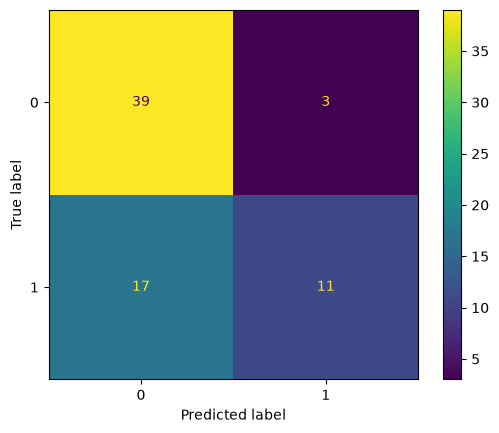

In [77]:
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, 
    y_pred=y_predsNB,
)

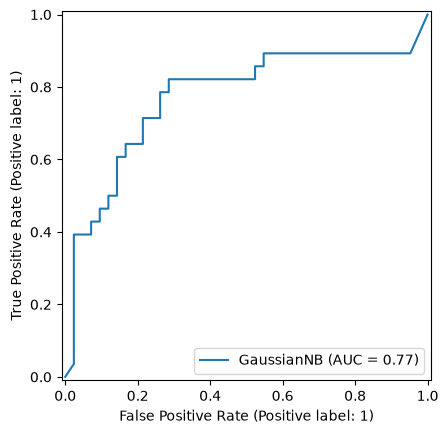

In [78]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clfNB,
                                                  X=X_test,
                                                  y=y_test)

# Redes Neurais

In [79]:
from sklearn.neural_network import MLPClassifier
clfMLP = MLPClassifier()
clfMLP.get_params()


{'activation': 'relu',
 'alpha': 0.0001,
 'batch_size': 'auto',
 'beta_1': 0.9,
 'beta_2': 0.999,
 'early_stopping': False,
 'epsilon': 1e-08,
 'hidden_layer_sizes': (100,),
 'learning_rate': 'constant',
 'learning_rate_init': 0.001,
 'max_fun': 15000,
 'max_iter': 200,
 'momentum': 0.9,
 'n_iter_no_change': 10,
 'nesterovs_momentum': True,
 'power_t': 0.5,
 'random_state': None,
 'shuffle': True,
 'solver': 'adam',
 'tol': 0.0001,
 'validation_fraction': 0.1,
 'verbose': False,
 'warm_start': False}

In [80]:
clfMLP.fit(X_train,y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",200
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",None


In [81]:
clfMLP.score(X=X_train,y=y_train)

0.8229665071770335

In [82]:
clfMLP.score(X=X_test,y=y_test)

0.8

In [83]:
y_predsMLP = clfMLP.predict(X_test)
y_predsMLP

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 1, 1])

In [84]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
conf_matMLP = confusion_matrix(y_test, y_predsMLP)
conf_matMLP

array([[36,  6],
       [ 8, 20]])

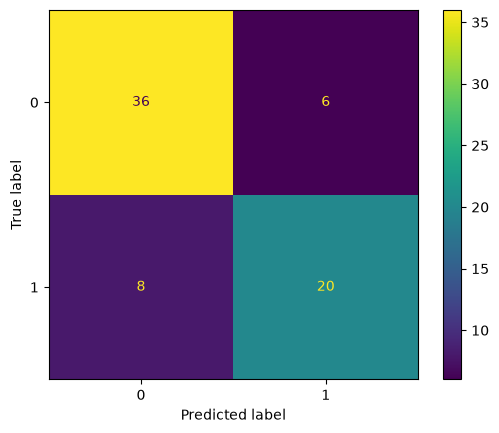

In [85]:
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, 
    y_pred=y_predsMLP,
)

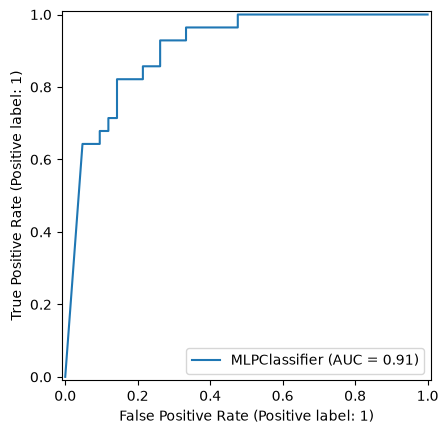

In [86]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clfMLP,
                                                  X=X_test,
                                                  y=y_test)

# K-Nearest Neighbors (KNN)

In [87]:
from sklearn.neighbors import KNeighborsClassifier
clfKNN = KNeighborsClassifier()
clfKNN.get_params()

{'algorithm': 'auto',
 'leaf_size': 30,
 'metric': 'minkowski',
 'metric_params': None,
 'n_jobs': None,
 'n_neighbors': 5,
 'p': 2,
 'weights': 'uniform'}

In [88]:
clfKNN.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [89]:
clfKNN.score(X=X_train,y=y_train)

0.8947368421052632

In [90]:
clfKNN.score(X=X_test,y=y_test)

0.8428571428571429

In [91]:
y_predsKNN = clfKNN.predict(X_test)
y_predsKNN

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1])

In [92]:
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
conf_matKNN = confusion_matrix(y_test, y_predsKNN)
conf_matKNN

array([[40,  2],
       [ 9, 19]])

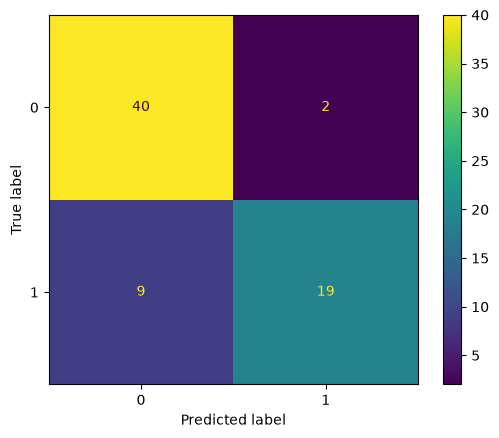

In [93]:
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test, 
    y_pred=y_predsKNN,
)

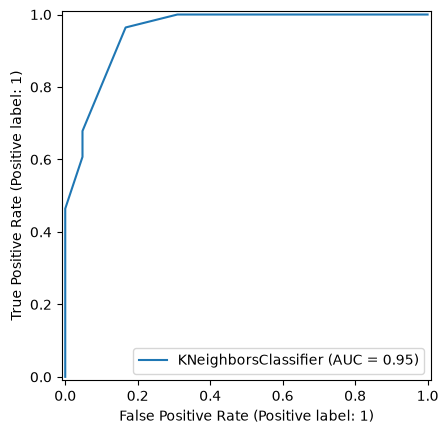

In [94]:
from sklearn.metrics import RocCurveDisplay
roc_curve_display = RocCurveDisplay.from_estimator(estimator=clfKNN,
                                                  X=X_test,
                                                  y=y_test)

# teste 2025

In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score



In [166]:
X_paraFILTRO

,C.R.,Frequência no Período,Média Final no Período,Percentual de Progresso,Período Atual,Idade,Renda Per Capita,Anos apos EM,Ano de Ingresso,target,...,Município de Residência_Passo do Sobrado-RS,Município de Residência_Rio Pardo-RS,Município de Residência_Santa Cruz do Sul-RS,Município de Residência_Sinimbu-RS,Município de Residência_Sobradinho-RS,Município de Residência_Taquari-RS,Município de Residência_Vale Verde-RS,Município de Residência_Venâncio Aires-RS,Município de Residência_Vera Cruz-RS,Município de Residência_Xangri-La-RS
0,469,0.00,0.0,29.00,3,42,0.76,21,2023,1,...,False,False,False,False,False,False,False,True,False,False
1,248,0.00,0.0,2.86,1,22,NaN,0,2025,1,...,False,False,False,False,False,False,False,True,False,False
2,872,97.89,6.0,81.19,6,21,2.05,1,2024,0,...,False,False,False,False,False,False,False,True,False,False
3,0,100.00,0.0,NaN,1,57,0.65,40,2025,1,...,False,False,False,False,False,False,False,True,False,False
4,76,0.00,0.0,0.00,1,26,NaN,6,2024,1,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
274,510,50.68,0.0,15.93,2,36,1.74,9,2024,0,...,False,False,False,False,False,False,False,True,False,False
275,503,88.57,7.5,7.59,1,42,NaN,25,2026,0,...,False,False,False,False,False,False,False,True,False,False
276,600,73.46,0.0,32.24,3,36,2.78,11,2024,0,...,False,False,False,False,False,False,False,True,False,False
277,145,0.00,0.0,2.00,1,31,NaN,9,2024,1,...,False,False,False,False,False,False,False,False,False,False


In [171]:
# filtrando por ano 
train_mask_X = X_paraFILTRO[X_paraFILTRO['Ano de Ingresso'].isin([2022, 2023, 2024])]
y_2022_23_24 = train_mask_X["target"]

X_2022_23_24 = train_mask_X.drop(["target"], axis=1)
X_2022_23_24

,C.R.,Frequência no Período,Média Final no Período,Percentual de Progresso,Período Atual,Idade,Renda Per Capita,Anos apos EM,Ano de Ingresso,Forma de Ingresso_ENEM - L1,...,Município de Residência_Passo do Sobrado-RS,Município de Residência_Rio Pardo-RS,Município de Residência_Santa Cruz do Sul-RS,Município de Residência_Sinimbu-RS,Município de Residência_Sobradinho-RS,Município de Residência_Taquari-RS,Município de Residência_Vale Verde-RS,Município de Residência_Venâncio Aires-RS,Município de Residência_Vera Cruz-RS,Município de Residência_Xangri-La-RS
0,469,0.00,0.0,29.00,3,42,0.76,21,2023,False,...,False,False,False,False,False,False,False,True,False,False
2,872,97.89,6.0,81.19,6,21,2.05,1,2024,False,...,False,False,False,False,False,False,False,True,False,False
4,76,0.00,0.0,0.00,1,26,NaN,6,2024,False,...,False,False,True,False,False,False,False,False,False,False
5,21,0.00,0.0,0.00,1,21,NaN,1,2024,False,...,False,False,True,False,False,False,False,False,False,False
6,0,0.00,0.0,0.00,1,32,NaN,3,2022,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269,0,0.00,0.0,NaN,1,21,NaN,1,2024,False,...,False,False,False,False,False,False,False,True,False,False
270,0,0.00,0.0,0.00,1,39,NaN,19,2024,False,...,False,False,False,False,False,False,False,False,False,False
274,510,50.68,0.0,15.93,2,36,1.74,9,2024,False,...,False,False,False,False,False,False,False,True,False,False
276,600,73.46,0.0,32.24,3,36,2.78,11,2024,False,...,False,False,False,False,False,False,False,True,False,False


In [172]:
y_2022_23_24

0      1
2      0
4      1
5      1
6      1
      ..
269    1
270    1
274    0
276    0
277    1
Name: target, Length: 125, dtype: int64

In [173]:
test_mask_X = X_paraFILTRO[X_paraFILTRO['Ano de Ingresso'].isin([2025])]
y_2025 = test_mask_X["target"]

X_2025 = test_mask_X.drop(["target"], axis=1)
X_2025

,C.R.,Frequência no Período,Média Final no Período,Percentual de Progresso,Período Atual,Idade,Renda Per Capita,Anos apos EM,Ano de Ingresso,Forma de Ingresso_ENEM - L1,...,Município de Residência_Passo do Sobrado-RS,Município de Residência_Rio Pardo-RS,Município de Residência_Santa Cruz do Sul-RS,Município de Residência_Sinimbu-RS,Município de Residência_Sobradinho-RS,Município de Residência_Taquari-RS,Município de Residência_Vale Verde-RS,Município de Residência_Venâncio Aires-RS,Município de Residência_Vera Cruz-RS,Município de Residência_Xangri-La-RS
1,248,0.00,0.0,2.86,1,22,NaN,0,2025,False,...,False,False,False,False,False,False,False,True,False,False
3,0,100.00,0.0,NaN,1,57,0.65,40,2025,False,...,False,False,False,False,False,False,False,True,False,False
11,353,0.00,0.0,0.00,1,24,0.74,6,2025,False,...,False,False,False,False,False,False,False,True,False,False
18,763,89.28,0.0,31.43,2,21,1.52,2,2025,False,...,False,False,False,False,False,False,False,True,False,False
19,923,91.86,0.0,51.19,4,26,1.52,7,2025,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
262,750,91.39,10.0,28.45,4,20,NaN,1,2025,False,...,False,False,False,False,False,False,False,True,False,False
264,199,0.00,0.0,5.69,1,25,0.89,7,2025,False,...,False,False,False,False,False,False,False,True,False,False
268,169,0.00,0.0,2.65,1,28,1.14,10,2025,False,...,False,False,False,False,False,False,False,True,False,False
271,735,91.37,9.2,19.72,2,39,1.52,20,2025,False,...,False,False,False,False,False,False,False,True,False,False


In [174]:
y_2025

1      1
3      1
11     1
18     0
19     0
      ..
262    0
264    1
268    1
271    0
278    0
Name: target, Length: 73, dtype: int64

In [175]:
# 2. Treinamento do Modelo de Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_2022_23_24, y_2022_23_24)


RandomForestClassifier(class_weight='balanced', random_state=42)

In [179]:
rf_model.score(X=X_2025,y=y_2025)

0.821917808219178

In [176]:

# 3. Predição para a turma de 2025
y_pred_2025 = rf_model.predict(X_2025)
y_proba_2025 = rf_model.predict_proba(X_2025)[:, 1]

# 4. Avaliação dos resultados da predição de 2025
print("=== Relatório de Avaliação (Ano de Ingresso 2025) ===")
print(classification_report(y_2025, y_pred_2025))
print("ROC-AUC Score:", roc_auc_score(y_2025, y_proba_2025))



=== Relatório de Avaliação (Ano de Ingresso 2025) ===
              precision    recall  f1-score   support

           0       1.00      0.71      0.83        45
           1       0.68      1.00      0.81        28

    accuracy                           0.82        73
   macro avg       0.84      0.86      0.82        73
weighted avg       0.88      0.82      0.82        73

ROC-AUC Score: 0.986904761904762


In [181]:
conf_mat = confusion_matrix(y_2025, y_pred_2025)
conf_mat



array([[32, 13],
       [ 0, 28]])

In [182]:
pd.crosstab(y_2025,
y_pred_2025,
rownames=["Target real"],
colnames=["Target predito"])

Target predito,0,1
Target real,,
0,32,13
1,0,28



=== Top 10 Parâmetros de Maior Influência na Evasão ===
                                                  Feature  Importancia
                                  Percentual de Progresso     0.276782
                                                     C.R.     0.178800
                                            Período Atual     0.140772
                                    Frequência no Período     0.101983
                                   Média Final no Período     0.094548
                                         Renda Per Capita     0.063886
                                                    Idade     0.029756
                                             Anos apos EM     0.020440
                                          Ano de Ingresso     0.018211
Forma de Ingresso_Processo Seletivo - Escola Pública - L4     0.007599


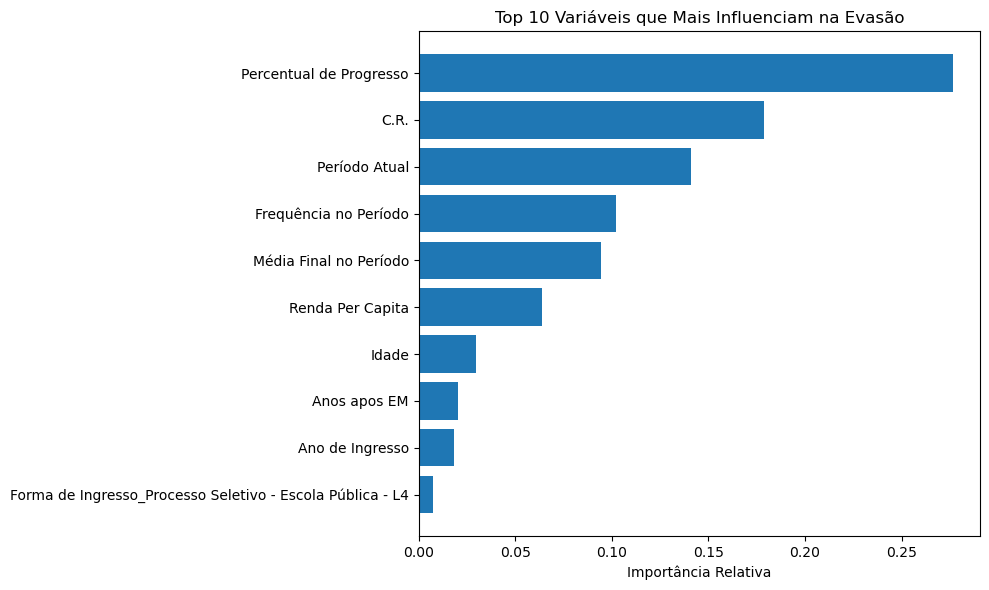

In [183]:
# 5. Análise dos Parâmetros Mais Influentes (Feature Importances)
importances = rf_model.feature_importances_
feature_names = X.columns

importances_df = pd.DataFrame({
    'Feature': feature_names,
    'Importancia': importances
}).sort_values(by='Importancia', ascending=False)

# Exibe os 10 parâmetros de maior impacto na evasão
print("\n=== Top 10 Parâmetros de Maior Influência na Evasão ===")
print(importances_df.head(10).to_string(index=False))

# Plotagem dos recursos mais relevantes
plt.figure(figsize=(10, 6))
plt.barh(importances_df['Feature'].head(10)[::-1], importances_df['Importancia'].head(10)[::-1])
plt.xlabel('Importância Relativa')
plt.title('Top 10 Variáveis que Mais Influenciam na Evasão')
plt.tight_layout()
plt.show()